# PrintGPT's LangGraph agentic generation workflow

This notebook explains the **implemented** PrintGPT image-completion agent in plain language and then runs it offline. The graph asks for two continuation candidates, turns each provider image into safe proposed ink, validates that ink deterministically, asks a visual critic to assess only the sanitized preview, permits at most one revision per candidate, and ranks the eligible results.

The run is fully deterministic: it uses the repository's generator and critic doubles, the real Track A mask builder and validator, and the real compiled LangGraph workflow. It makes **no Gemini request**, needs no API key, and never approves, exports, or prints a candidate.

Relevant implementation: [`graph.py`](../src/printgpt_generation/graph.py), [`docs/generation.md`](../docs/generation.md), and [`pipeline.py`](../src/printgpt_mvp/pipeline.py).


In [1]:
from __future__ import annotations

from dataclasses import asdict
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image, ImageDraw, ImageFont

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "pyproject.toml").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "pyproject.toml").is_file():
    raise RuntimeError("Run this notebook from the PrintGPT repository or notebooks directory")

SOURCE_ROOT = PROJECT_ROOT / "src"
if str(SOURCE_ROOT) not in sys.path:
    sys.path.insert(0, str(SOURCE_ROOT))

from printgpt_alignment import A4CalibrationLayout
from printgpt_generation.config import GenerationConfig
from printgpt_generation.doubles import (
    CriticScript,
    DeterministicCritic,
    DeterministicGenerator,
    GeneratorBehavior,
)
from printgpt_generation.example import synthetic_page
from printgpt_generation.graph import GraphDependencies, build_generation_graph, initial_state
from printgpt_generation.providers import FixedStepClock, SequentialIdProvider
from printgpt_generation.requests import create_generation_request
from printgpt_generation.track_a import TrackAValidator
from printgpt_masking import build_masks

LAYOUT = A4CalibrationLayout(dpi=100.0)
print(f"Repository: {PROJECT_ROOT}")
print(f"Demo canvas: {LAYOUT.raster_width_px} x {LAYOUT.raster_height_px} px at {LAYOUT.dpi:.0f} DPI")
print("Network/API use: none")


Repository: C:\Users\saroy\Codes\PrintGPT-langgraph-agent-notebook
Demo canvas: 827 x 1169 px at 100 DPI
Network/API use: none


## 1. What the agentic system does

In everyday terms, PrintGPT treats image generation as **proposal**, not permission. A generator proposes a completed page. Deterministic code then checks framing, extracts only genuinely new dark ink, clips it to the printable region, and rejects unsafe proposals. A critic judges the sanitized result that could actually be printed. LangGraph coordinates those steps, allows one evidence-based retry, and produces a ranked shortlist for a person.

| Part | Responsibility | What it does **not** do |
| --- | --- | --- |
| **LangGraph orchestration** | Moves typed state through bounded nodes and routes | It does not create pixels or decide print safety itself |
| **Image generator** | Proposes a complete-page continuation | It does not approve or print anything |
| **Deterministic validator** | Clips proposed ink to allowed, safe pixels and records measurable violations | It does not judge artistic quality |
| **Visual critic** | Scores continuity, style, geometry, and relevance from the sanitized preview | It cannot override validation |
| **Revision decision** | Converts geometry, validation, or critic feedback into one bounded retry | It cannot create an open-ended loop |
| **Final candidate ranking** | Selects an eligible attempt per candidate and orders the survivors deterministically | Ranking is not human approval |

The boundaries are implemented in [`providers.py`](../src/printgpt_generation/providers.py), [`track_a.py`](../src/printgpt_generation/track_a.py), [`critic.py`](../src/printgpt_generation/critic.py), and [`ranking.py`](../src/printgpt_generation/ranking.py).


## 2. The actual graph

```text
prepare
→ generate two candidates
→ select candidate
→ normalize and extract new ink
→ validate
→ criticize
→ decide whether to revise
→ optionally generate one revision
→ normalize, validate, and criticize again
→ process the next candidate
→ rank eligible candidates
→ finish
```

The implementation names are `prepare_run`, `generate_initial_candidates`, `select_next_attempt`, `normalize_candidate`, `validate_candidate`, `criticize_candidate`, `decide_revision`, `generate_revision`, and `rank_candidates`. Failures skip stages that cannot safely run and flow to the revision decision. See [`build_generation_graph`](../src/printgpt_generation/graph.py).


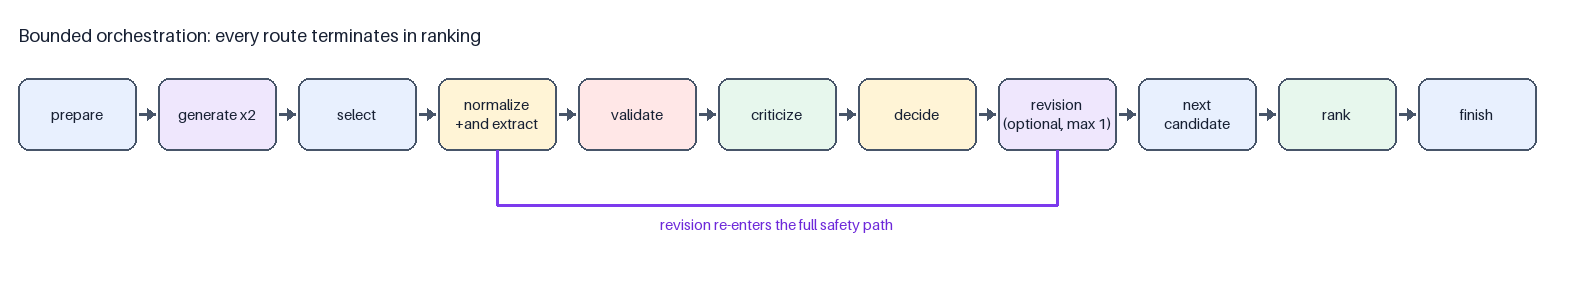

In [2]:
def graph_diagram() -> Image.Image:
    labels = [
        "prepare", "generate x2", "select", "normalize\n+and extract", "validate",
        "criticize", "decide", "revision\n(optional, max 1)", "next\ncandidate", "rank", "finish",
    ]
    colours = [
        "#e8f0fe", "#efe7fd", "#e8f0fe", "#fff4d6", "#ffe7e7",
        "#e7f7ed", "#fff4d6", "#efe7fd", "#e8f0fe", "#e7f7ed", "#e8f0fe",
    ]
    canvas = Image.new("RGB", (1580, 300), "white")
    draw = ImageDraw.Draw(canvas)
    font = ImageFont.load_default(size=18)
    small = ImageFont.load_default(size=15)
    box_w, box_h, gap, top = 118, 72, 22, 78
    for index, (label, colour) in enumerate(zip(labels, colours)):
        x = 18 + index * (box_w + gap)
        draw.rounded_rectangle((x, top, x + box_w, top + box_h), radius=11, fill=colour, outline="#475569", width=2)
        draw.multiline_text((x + box_w / 2, top + box_h / 2), label, fill="#172033", font=small, anchor="mm", align="center")
        if index < len(labels) - 1:
            start, end, y = x + box_w + 3, x + box_w + gap - 3, top + box_h / 2
            draw.line((start, y, end, y), fill="#475569", width=3)
            draw.polygon([(end, y), (end - 8, y - 6), (end - 8, y + 6)], fill="#475569")
    # The revision returns to normalization; completing an attempt returns to selection.
    revision_x = 18 + 7 * (box_w + gap) + box_w / 2
    normalize_x = 18 + 3 * (box_w + gap) + box_w / 2
    draw.line((revision_x, top + box_h, revision_x, 205, normalize_x, 205, normalize_x, top + box_h), fill="#7c3aed", width=3)
    draw.text(((revision_x + normalize_x) / 2, 215), "revision re-enters the full safety path", fill="#6d28d9", font=small, anchor="ma")
    draw.text((18, 24), "Bounded orchestration: every route terminates in ranking", fill="#172033", font=font)
    return canvas

display(graph_diagram())


### Node-by-node contract

| Node | Main input | Partial state output | Dependency/function called | Possible next route |
| --- | --- | --- | --- | --- |
| `prepare_run` | request | run ID, start time, resolved prompt, guidance image | ID provider, clock, `resolve_user_prompt`, `render_region_guidance` | generate initial candidates |
| `generate_initial_candidates` | request, prompt, guidance | two attempt records, candidate IDs, queue, counters | `CandidateGenerator.generate` through bounded retries | select next attempt |
| `select_next_attempt` | pending queue | active attempt and shortened queue | none | attempt's required stage, or ranking |
| `normalize_candidate` | raw generated image | normalized page, proposed new-ink mask, registration/extraction record | `normalize_and_extract` | validate, or revision decision on geometry rejection |
| `validate_candidate` | proposed new-ink mask and Track A masks | validation summary, sanitized mask, composed preview | `CandidateValidator.validate` and `compose_preview` | criticize if accepted; otherwise revision decision |
| `criticize_candidate` | original, guidance, sanitized preview | parsed critic outcome and counters | `VisualCritic.critique`, `parse_critic_output`, `to_verdict` | revision decision |
| `decide_revision` | current attempt plus revision count | `RevisionDecision` | `ranking.decide_revision` | generate one revision, or process next candidate |
| `generate_revision` | feedback and previous candidate | new revision attempt and incremented revision count | `CandidateGenerator.generate` | normalize, or decision if generation failed |
| `rank_candidates` | all candidate/attempt records | terminal `RunOutcome` and finish time | `ranking.build_outcome` | finish |

Nodes return partial immutable-style replacements rather than mutating attempt records. Routing keys off [`AttemptStatus`](../src/printgpt_generation/models.py), not free-form model text.


## 3. What lives in graph state

[`GenerationGraphState`](../src/printgpt_generation/graph.py) is the workflow's shared memory.

| State field | Meaning |
| --- | --- |
| `request` | Immutable canonical RGB page, Track A mask bundle, optional user prompt, and seed |
| `run_id`, timestamps, `prompt`, `guidance_image` | Run identity and prepared inputs |
| `candidate_ids` | Stable order of the two logical candidates |
| `attempts` | Immutable `AttemptRecord` snapshots for initial attempts, revisions, and failures |
| `pending_attempt_ids` | Processing queue for initial attempts |
| `active_attempt_id` | The attempt currently moving through nodes |
| `revision_counts` | Semantic revisions used per candidate; transport retries are separate |
| `counters` | Logical generator requests, critic requests, and provider transport attempts |
| `outcome` | Ranked terminal result, set only by `rank_candidates` |

An attempt record can accumulate raw generation, normalization and extraction evidence, validation evidence, sanitized ink, critic evidence, and a revision decision. It never changes meaning silently: nodes replace the frozen record with a new value. See [`models.py`](../src/printgpt_generation/models.py) and [`requests.py`](../src/printgpt_generation/requests.py).


## 4. Dependency injection: same graph, different providers

`GraphDependencies` supplies `generator`, `validator`, `critic`, `clock`, `ids`, and `config`. The graph only relies on their small interfaces, so tests and offline demos can be reproducible while a live adapter can be substituted without editing graph topology.

| Interface | Role | Offline implementation | Live/production-oriented implementation |
| --- | --- | --- | --- |
| `CandidateGenerator` | Return a candidate page | `DeterministicGenerator` | `GeminiImageGenerator` |
| `CandidateValidator` | Enforce masks and compose the exact preview | `TrackAValidator` (real deterministic validation); `SimulatedValidator` exists for isolated tests | Same `TrackAValidator` |
| `VisualCritic` | Return structured quality feedback | `DeterministicCritic` | `GeminiVisualCritic` |
| `Clock` | Timestamp calls and runs | `FixedStepClock` | `SystemClock` |
| `IdProvider` | Create stable run/candidate IDs | `SequentialIdProvider` | `UuidIdProvider` |

The doubles in [`doubles.py`](../src/printgpt_generation/doubles.py) exist to make pixels, decisions, failures, call ordering, and revision paths reproducible without network access or cost. They also record calls, which lets this notebook prove what the critic actually saw.


## 5. Offline demonstration setup

The source page and allowed region come from the repository's existing synthetic example. Track A builds all masks. Candidate 1 is told by the scripted critic to revise; candidate 2 initially draws outside the printable region and is revised after deterministic validation rejects it. Both revisions must re-enter normalization, validation, and criticism.

> The notebook uses a 100-DPI A4 layout to keep execution and embedded output compact. The default application layout is 300 DPI; all safety distances are expressed physically and converted by the repository.


In [3]:
page, allowed_region = synthetic_page(LAYOUT)
masks = build_masks(page, allowed_region, layout=LAYOUT)
config = GenerationConfig(layout=LAYOUT)
request = create_generation_request(
    page,
    masks,
    user_prompt="Continue the unfinished line drawing naturally.",
    config=config,
    seed=7,
)

generator = DeterministicGenerator({
    (1, 0): GeneratorBehavior.OUTSIDE_REGION,
})
critic = DeterministicCritic({
    (0, 0): CriticScript.revise(4.5, "Follow the existing contour with a cleaner continuation."),
    (0, 1): CriticScript.accept(8.7),
    (1, 1): CriticScript.accept(8.2),
})
deps = GraphDependencies(
    generator=generator,
    validator=TrackAValidator(),
    critic=critic,
    clock=FixedStepClock(),
    ids=SequentialIdProvider(),
    config=config,
)

print("Request valid:", request.canonical_page.shape == (*LAYOUT.image_shape, 3))
print("Printable pixels:", int(np.count_nonzero(masks.printable_region_mask)))
print("Validation adapter is simulated:", deps.validator.simulated)


Request valid: True
Printable pixels: 359463
Validation adapter is simulated: False


## 6. Stream the real compiled LangGraph

`build_generation_graph` returns the same compiled graph used by `run_generation`. Streaming `updates` exposes each node transition. The small accumulator below only records those partial state updates for teaching; all generation, normalization, validation, criticism, revision, and ranking work remains inside repository functions.


In [4]:
graph = build_generation_graph(deps)
start_state = initial_state(request)
final_state = dict(start_state)
progression = []

for event in graph.stream(
    start_state,
    config={"recursion_limit": config.recursion_limit},
    stream_mode="updates",
):
    for node_name, update in event.items():
        final_state.update(update)
        active_id = final_state["active_attempt_id"]
        active = next((item for item in final_state["attempts"] if item.attempt_id == active_id), None)
        progression.append({
            "step": len(progression) + 1,
            "node": node_name,
            "active attempt": active_id or "—",
            "status after node": active.status.value if active else "—",
            "queued": len(final_state["pending_attempt_ids"]),
            "revisions used": sum(final_state["revision_counts"].values()),
        })

outcome = final_state["outcome"]
assert outcome is not None
assert len(final_state["candidate_ids"]) == 2
assert sum(final_state["revision_counts"].values()) >= 1
assert outcome.requires_user_approval is True

display(pd.DataFrame(progression))


,step,node,active attempt,status after node,queued,revisions used
0,1,prepare_run,—,—,0,0
1,2,generate_initial_candidates,—,—,2,0
2,3,select_next_attempt,candidate-1/attempt-0,generated,1,0
3,4,normalize_candidate,candidate-1/attempt-0,extracted,1,0
4,5,validate_candidate,candidate-1/attempt-0,validated,1,0
5,6,criticize_candidate,candidate-1/attempt-0,criticized,1,0
6,7,decide_revision,candidate-1/attempt-0,criticized,1,0
7,8,generate_revision,candidate-1/attempt-1,generated,1,1
8,9,normalize_candidate,candidate-1/attempt-1,extracted,1,1
9,10,validate_candidate,candidate-1/attempt-1,validated,1,1


The trace shows two different reasons for revision. Candidate 1 reaches the critic, receives semantic feedback, and revises. Candidate 2 is rejected by deterministic validation before criticism; its concrete safety reasons become revision feedback. A revised attempt is not trusted merely because it is a retry—it traverses normalization, validation, and criticism again.


## 7. Source page, masks, and graph-produced guidance

The generator and critic receive the original page plus a separate region-guidance image. Guidance is never printable. Green identifies the printable region, red identifies forbidden areas, and the magenta outline is also guidance only.


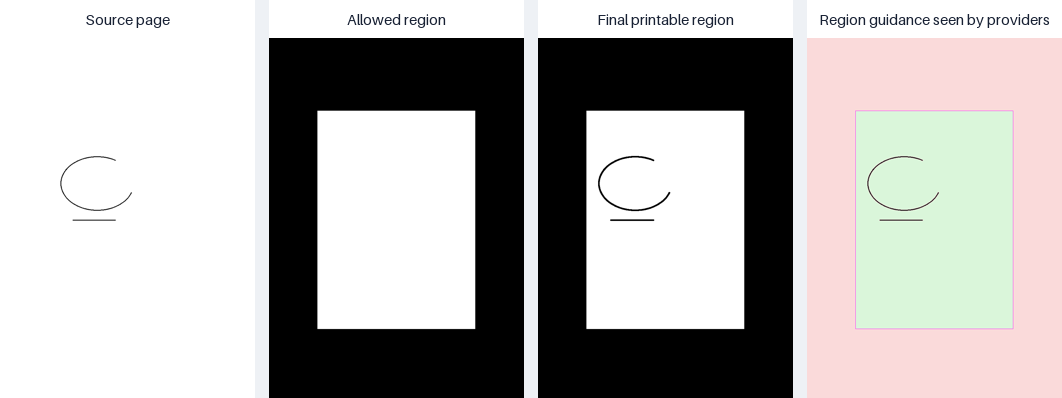

In [5]:
def labelled_panel(array: np.ndarray, title: str, height: int = 360) -> Image.Image:
    image = Image.fromarray(array).convert("RGB")
    ratio = height / image.height
    image = image.resize((max(1, round(image.width * ratio)), height))
    panel = Image.new("RGB", (image.width, image.height + 38), "white")
    panel.paste(image, (0, 38))
    ImageDraw.Draw(panel).text(
        (panel.width / 2, 19), title, fill="#172033", anchor="mm", font=ImageFont.load_default(size=15)
    )
    return panel

def panel_row(items: list[tuple[np.ndarray, str]], height: int = 360) -> Image.Image:
    panels = [labelled_panel(array, title, height) for array, title in items]
    gap = 14
    row = Image.new("RGB", (sum(item.width for item in panels) + gap * (len(panels) - 1), max(item.height for item in panels)), "#eef1f5")
    x = 0
    for panel in panels:
        row.paste(panel, (x, 0))
        x += panel.width + gap
    return row

display(panel_row([
    (page, "Source page"),
    (masks.allowed_region_mask, "Allowed region"),
    (masks.printable_region_mask, "Final printable region"),
    (final_state["guidance_image"], "Region guidance seen by providers"),
]))


## 8. Attempt statuses and deterministic validation

| Attempt status | Meaning | Normal next route |
| --- | --- | --- |
| `generated` | Provider returned an image | normalize |
| `generation_failed` | Provider call failed or budget was exhausted | revision decision |
| `geometry_rejected` | Output framing/registration was unsafe | revision decision |
| `extracted` | Output was normalized and proposed new ink was extracted | validate |
| `validation_rejected` | Sanitized result failed deterministic thresholds | revision decision; critic is skipped |
| `validated` | Deterministic validation accepted the sanitized mask | criticize |
| `critic_failed` | Critic transport or schema parsing failed | revision decision; not semantically revisable |
| `criticized` | A structured verdict was produced | revision decision |

Validation happens before criticism because geometry and mask membership are objective constraints. The validator clips the proposed mask and composes `preview_rgb` from the source page plus **only sanitized new ink**. The critic therefore judges the visible candidate that could proceed to human review, not unsafe pixels from the raw generator output. See [`validate_candidate`](../src/printgpt_generation/graph.py) and [`CritiqueCall`](../src/printgpt_generation/providers.py).


In [6]:
attempt_rows = []
for attempt in final_state["attempts"]:
    extraction = attempt.normalization.extraction if attempt.normalization else None
    validation = attempt.validation
    attempt_rows.append({
        "attempt": attempt.attempt_id,
        "kind": attempt.kind.value,
        "final status": attempt.status.value,
        "proposed new-ink px": extraction.new_ink_pixels if extraction else None,
        "sanitized ink px": validation.metrics.get("final_ink_count") if validation else None,
        "removed fraction": round(float(validation.metrics.get("removed_fraction", 0.0)), 3) if validation else None,
        "validation": "accepted" if validation and validation.accepted else ("rejected" if validation else "not run"),
        "validation reasons": "; ".join(validation.reasons) if validation else "—",
    })

display(pd.DataFrame(attempt_rows))


,attempt,kind,final status,proposed new-ink px,sanitized ink px,removed fraction,validation,validation reasons
0,candidate-1/attempt-0,initial,criticized,491,491,0.0,accepted,
1,candidate-2/attempt-0,initial,validation_rejected,1991,0,1.0,rejected,"sanitized addition has 0 ink pixels, below min..."
2,candidate-1/attempt-1,revision,criticized,533,533,0.0,accepted,
3,candidate-2/attempt-1,revision,criticized,617,617,0.0,accepted,


### Raw page → proposed ink → sanitized ink → preview

`candidate_new_ink_mask` is the proposal extracted by [`normalize_and_extract`](../src/printgpt_generation/extraction.py). `sanitized_new_ink_mask` is the validator's clipped output. `preview_rgb` is the source page with that sanitized mask composed in black. These are deliberately different artifacts.


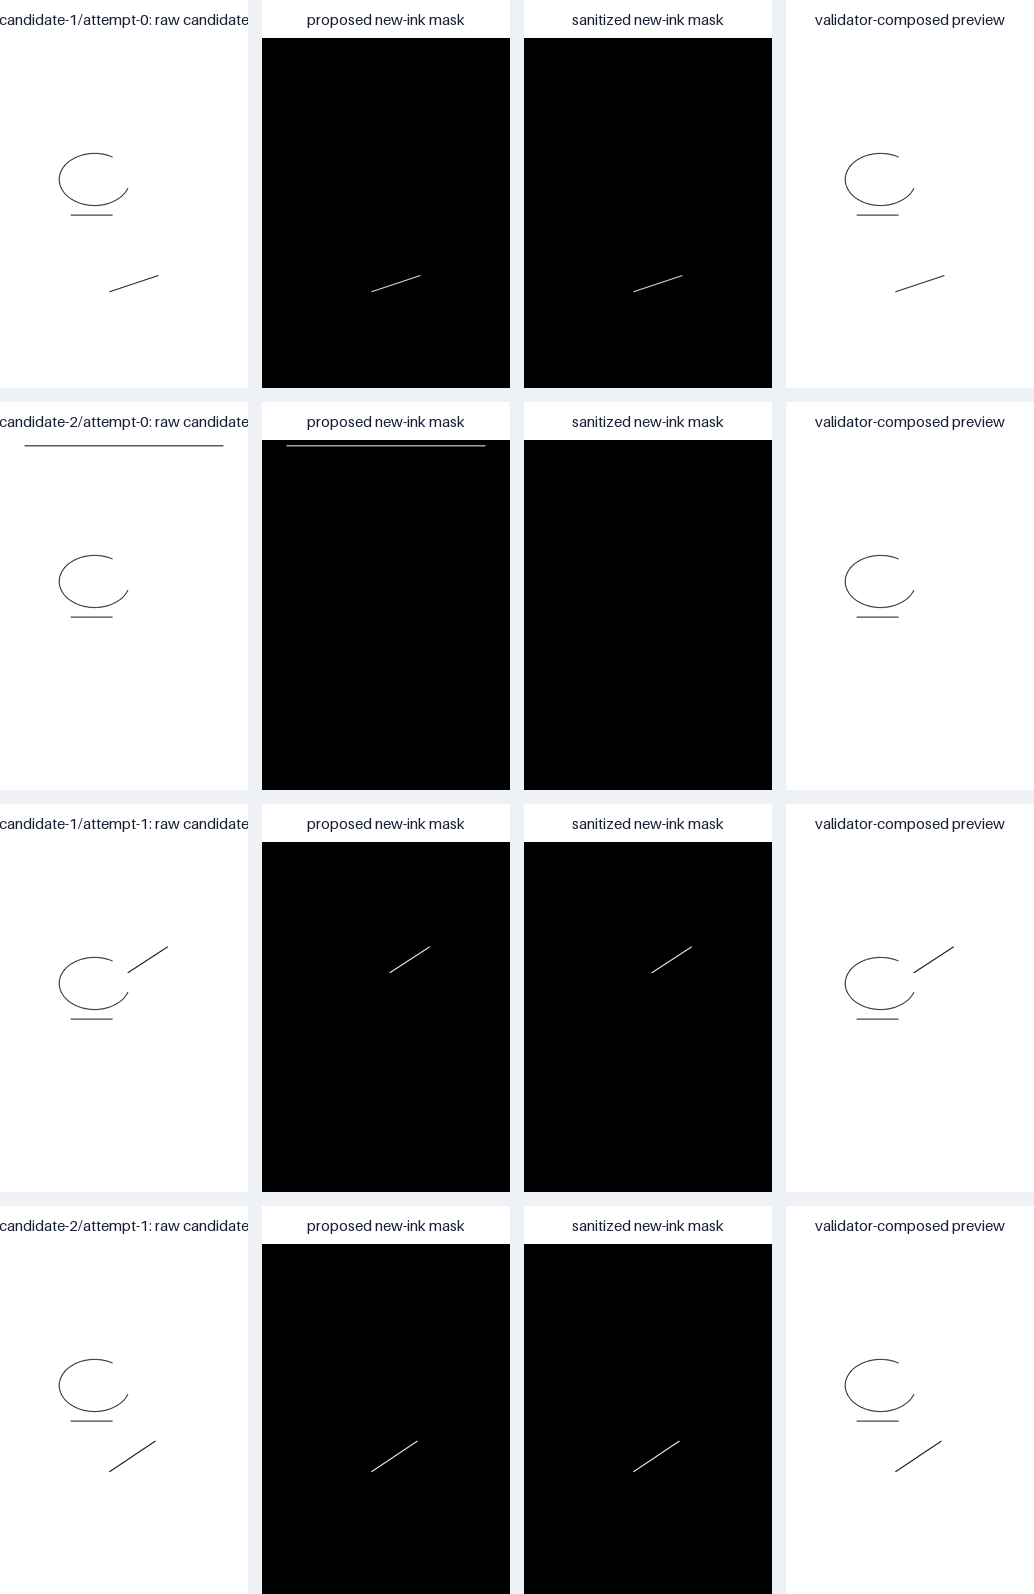

In [7]:
attempts = list(final_state["attempts"])
attempt_rows_visual = []
for attempt in attempts:
    raw = attempt.generation.output.image if attempt.generation.output else np.full((*LAYOUT.image_shape, 3), 255, np.uint8)
    proposed = attempt.normalized.candidate_new_ink_mask if attempt.normalized else np.zeros(LAYOUT.image_shape, np.uint8)
    sanitized = attempt.sanitized_new_ink_mask if attempt.sanitized_new_ink_mask is not None else np.zeros(LAYOUT.image_shape, np.uint8)
    preview = attempt.preview_rgb if attempt.preview_rgb is not None else page
    row = panel_row([
        (raw, f"{attempt.attempt_id}: raw candidate"),
        (proposed, "proposed new-ink mask"),
        (sanitized, "sanitized new-ink mask"),
        (preview, "validator-composed preview"),
    ], height=350)
    attempt_rows_visual.append(row)

canvas = Image.new(
    "RGB",
    (max(row.width for row in attempt_rows_visual), sum(row.height for row in attempt_rows_visual) + 14 * (len(attempt_rows_visual) - 1)),
    "#eef1f5",
)
y = 0
for row in attempt_rows_visual:
    canvas.paste(row, (0, y))
    y += row.height + 14
display(canvas)


## 9. What the critic actually saw

The deterministic critic records every `CritiqueCall`. Candidate 2's rejected initial attempt is absent because invalid proposals never reach criticism. The remaining images below are the exact `sanitized_preview` arrays passed to the critic—not reconstructed approximations.


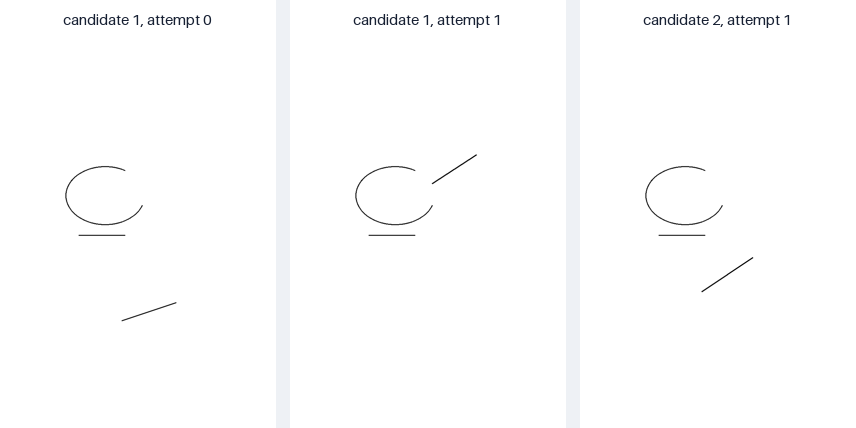

Critic call keys: [(0, 0), (0, 1), (1, 1)]
Rejected candidate-2 initial attempt reached critic: False


In [8]:
critic_items = [
    (call.sanitized_preview, f"candidate {call.candidate_index + 1}, attempt {call.attempt_index}")
    for call in critic.calls
]
display(panel_row(critic_items, height=390))

print("Critic call keys:", [(call.candidate_index, call.attempt_index) for call in critic.calls])
print("Rejected candidate-2 initial attempt reached critic:", (1, 0) in [(c.candidate_index, c.attempt_index) for c in critic.calls])


In [9]:
critic_rows = []
for attempt in final_state["attempts"]:
    verdict = attempt.critic.verdict if attempt.critic and attempt.critic.verdict else None
    if verdict is None:
        continue
    critic_rows.append({
        "attempt": attempt.attempt_id,
        "overall": verdict.scores.score,
        "continuity": verdict.scores.boundary_continuity_score,
        "style": verdict.scores.style_match_score,
        "geometry": verdict.scores.geometry_plausibility_score,
        "recommendation": verdict.recommendation,
        "assessment": verdict.assessment.value,
        "problems": "; ".join(verdict.problems) or "—",
        "revision instruction": verdict.revision_instruction or "—",
    })

display(pd.DataFrame(critic_rows))


,attempt,overall,continuity,style,geometry,recommendation,assessment,problems,revision instruction
0,candidate-1/attempt-0,4.5,4.5,4.5,4.5,revise,needs_revision,continuation does not follow the existing contour,Follow the existing contour with a cleaner con...
1,candidate-1/attempt-1,8.7,7.5,7.5,7.5,accept,acceptable,—,—
2,candidate-2/attempt-1,8.2,7.5,7.5,7.5,accept,acceptable,—,—


## 10. Revision decisions and the one-revision limit

The first attempt can be revised after a geometry rejection, validation rejection, or non-acceptable critic verdict. Provider or critic failures are not revised because they provide no semantic feedback. Once a revision exists, `AttemptKind.REVISION`, `revision_counts`, and the conditional route independently prevent another revision. This is a semantic bound; the graph's recursion limit is only a last-resort guard.

Importantly, the revision is not grandfathered into eligibility. It must pass normalization/registration, new-ink extraction, deterministic validation, and structured criticism again. See [`decide_revision`](../src/printgpt_generation/ranking.py) and [`route_after_revision_decision`](../src/printgpt_generation/graph.py).


In [10]:
decision_rows = []
for attempt in final_state["attempts"]:
    decision = attempt.revision_decision
    decision_rows.append({
        "attempt": attempt.attempt_id,
        "attempt kind": attempt.kind.value,
        "decision": decision.kind.value if decision else "—",
        "reasons": "; ".join(decision.reasons) if decision else "—",
        "instruction": decision.instruction if decision and decision.instruction else "—",
    })

display(pd.DataFrame(decision_rows))
print("Revision counts:", dict(final_state["revision_counts"]))


,attempt,attempt kind,decision,reasons,instruction
0,candidate-1/attempt-0,initial,revise,continuation does not follow the existing contour,Follow the existing contour with a cleaner con...
1,candidate-2/attempt-0,initial,revise,"sanitized addition has 0 ink pixels, below min...",—
2,candidate-1/attempt-1,revision,limit_reached,revision limit reached,—
3,candidate-2/attempt-1,revision,limit_reached,revision limit reached,—


Revision counts: {'candidate-1': 1, 'candidate-2': 1}


## 11. Eligibility, selection, and ranking

| Eligibility condition | Why it is required |
| --- | --- |
| Attempt status is `criticized` | The full required path completed |
| Deterministic validation exists and is accepted | A critic cannot waive geometry or mask safety |
| A parsed critic verdict exists | Malformed or failed feedback is not rankable |
| Recommendation is not `reject` | Explicit visual rejection excludes the attempt |
| Overall and every sub-score meet configured thresholds | One strong score cannot hide a weak safety-relevant dimension |

For each logical candidate, [`select_attempt`](../src/printgpt_generation/ranking.py) keeps the revision only when it is eligible and scores at least as well as an eligible original; otherwise it keeps the eligible original. Selected attempts are ranked by overall critic score, mean sub-score, lower removed fraction, then original candidate order. These deterministic tie-breakers make reruns stable.


In [11]:
selection_rows = [asdict(item) for item in outcome.selections]
ranking_rows = [asdict(item) for item in outcome.ranked]

print("Per-candidate selection")
display(pd.DataFrame(selection_rows))
print("Final ranking")
display(pd.DataFrame(ranking_rows))
print("Terminal status:", outcome.status.value)


Per-candidate selection


,candidate_id,selected_attempt_id,reason
0,candidate-1,candidate-1/attempt-1,revision is eligible and not worse
1,candidate-2,candidate-2/attempt-1,revision is eligible and not worse


Final ranking


,rank,candidate_id,attempt_id,score,used_revision
0,1,candidate-1,candidate-1/attempt-1,8.7,True
1,2,candidate-2,candidate-2/attempt-1,8.2,True


Terminal status: candidates_ready


## 12. Call bounds and the human gate

Logical provider requests are counted separately from transport attempts. With two candidates and one allowed revision each, generation is bounded at four logical requests. Criticism runs only after accepted validation, so its count may be lower.


In [12]:
counters = final_state["counters"]
call_summary = pd.DataFrame([
    {"measure": "generator calls recorded by double", "value": len(generator.calls)},
    {"measure": "generation requests in graph state", "value": counters.generation_requests},
    {"measure": "critic calls recorded by double", "value": len(critic.calls)},
    {"measure": "critic requests in graph state", "value": counters.critic_requests},
    {"measure": "total provider transport attempts", "value": counters.provider_attempts},
])
display(call_summary)

assert len(generator.calls) == counters.generation_requests
assert len(critic.calls) == counters.critic_requests
assert outcome.requires_user_approval

print("requires_user_approval:", outcome.requires_user_approval)
print("Automatic approval performed: no")
print("Export or print operation invoked by this notebook: no")


,measure,value
0,generator calls recorded by double,4
1,generation requests in graph state,4
2,critic calls recorded by double,3
3,critic requests in graph state,3
4,total provider transport attempts,7


requires_user_approval: True
Automatic approval performed: no
Export or print operation invoked by this notebook: no


## 13. Deterministic doubles versus Gemini adapters

[`GeminiImageGenerator`](../src/printgpt_generation/gemini.py) and [`GeminiVisualCritic`](../src/printgpt_generation/gemini.py) implement the same two provider protocols as the doubles. Replacing the `generator` and `critic` fields in `GraphDependencies` changes provider behavior, not graph nodes, routes, validation, the revision limit, eligibility, or the human-approval requirement.

| Concern | Deterministic execution in this notebook | Gemini adapter execution |
| --- | --- | --- |
| Candidate pixels | Seeded local drawing behavior | Gemini image interaction through `GeminiImageGenerator` |
| Critic response | Scripted JSON text | Schema-constrained Gemini text through `GeminiVisualCritic`, still parsed as untrusted |
| Credentials/network | None | Client is created explicitly; credentials are read only then |
| Repeatability | Exact for the same calls and scripts | Provider behavior may vary |
| Graph structure | Unchanged | Unchanged |
| Deterministic validation and sanitized preview | Always retained | Always retained |
| Human approval | Mandatory | Mandatory |

This notebook intentionally does not construct a Gemini client, request an API key, or make a live call. The current Streamlit offline mode calls `run_offline_document`, whose `_offline_dependencies` wires `DeterministicGenerator` and `DeterministicCritic`; therefore it demonstrates the integrated workflow but **does not perform real AI image generation**. See [`streamlit_app.py`](../src/printgpt_mvp/streamlit_app.py) and [`pipeline.py`](../src/printgpt_mvp/pipeline.py).


## 14. Terminal outcomes

| Outcome | Meaning | Ranked candidates | Approval/export effect |
| --- | --- | --- | --- |
| `candidates_ready` | At least one candidate has an eligible selected attempt | Non-empty, best first | Still only proposals; `requires_user_approval=True` |
| `no_valid_candidate` | No attempt survived deterministic validation plus rankable criticism | Empty | Nothing can be selected automatically; reasons explain each candidate's last outcome |

Individual attempts may terminate as provider failure, geometry rejection, validation rejection, critic failure, critic rejection, or below-threshold criticism. `build_outcome` converts the complete evidence into exactly one of the two run statuses. Even `candidates_ready` is not “approved”; it means “ready for human review.”


## 15. Boundaries with the rest of PrintGPT

This graph begins after alignment has produced a canonical RGB A4 page and Track A has produced binary masks. It ends with ranked attempt records and sanitized new-ink masks. Alignment, scanning, printer calibration, Streamlit interaction, PDF export, and physical printing remain outside this notebook. The only relevant exchange is:

- **Inputs:** canonical RGB page, existing/protected/allowed/printable masks, prompt, seed, and configuration.
- **Outputs:** evidence-rich attempt records, sanitized masks, previews, ranking, and an explicit human-approval requirement.

That boundary prevents the visual model from acquiring hidden authority over alignment, safety masks, export, or the printer.


## What is implemented versus what remains

- **LangGraph orchestration is implemented.**
- **Deterministic offline generation and criticism are implemented.**
- **Mask validation and bounded revision are implemented.**
- **Gemini adapter classes exist.**
- **Real Gemini image generation still requires a successful live test and connection to the application.**
- **Human approval remains mandatory before export or printing.**

The executed trace, images, tables, and assertions above teach the agentic workflow without requiring the reader to inspect production code, while the file links make deeper inspection easy when desired.
